# Statistical methods for data analysis

[Pedro L. C. Rodrigues](https://plcrodrigues.github.io/) and [Thomas Moreau](https://tommoral.github.io/about.html) 

---

Everything we did earlier this week produced **point predictions**: a number, a
label, a score on a test set. 

This session is about the sentence that should come
right after a point prediction:

> *"...and here is what I can honestly claim about it."*

We will consider four practical questions and use four different statistical tools:

| Question | Tool | Guarantee |
|---|---|---|
| Is this coefficient different from zero? | $t$-test | exact, **if** the Gaussian linear model holds |
| Is *anything* here different from chance? | permutation test | exact, **if** the data are exchangeable under $H_0$ |
| Where will the next observation fall? | conformal prediction | marginal coverage, **if** the data are exchangeable |
| Can I interpret `predict_proba` as a probability? | calibration | none for free — it must be checked and fixed |

One important concept runs through the whole notebook: **exchangeability is the modern
replacement for normality**. 

### Datasets

We will consider two datasets, both standard in scikit-learn:

* **`diabetes`** (*n* = 442, 10 features) — regression, ten baseline clinical
  measurements against disease progression one year later
  
* **`digits`** (*n* = 1797, 64 features) — classification, 8×8 images of handwritten
  digits

A few controlled simulations appear where we need to *see* a phenomenon that real
data hides.

## Table of contents

* [A reminder: what a hypothesis test actually does](#reminder)
* [1 The classical linear model, and when to stop trusting it](#linearmodel)
    * [1.1 The assumptions, and how badly they fail here](#linearmodel_assumptions)
* [2 Permutation tests](#permutation)
    * [2.1 The idea](#permutation_idea)
    * [2.2 How many permutations?](#permutation_howmany)
    * [2.3 Permuting a partial coefficient: Freedman–Lane](#permutation_freedmanlane)
    * [2.4 The real payoff: testing a model that has no formula](#permutation_noformula)
* [3 Conformal prediction](#conformal)
    * [3.1 From testing to predicting](#conformal_testing)
    * [3.2 Split conformal prediction](#conformal_split)
    * [3.3 The hard limit: marginal ≠ conditional coverage](#conformal_conditional)
* [4 Probabilistic calibration of classifiers](#calibration)
    * [4.1 What `predict_proba` does and does not promise](#calibration_promise)
    * [4.2 Calibration curve](#calibration_curve)
    * [4.3 Fixing it: post-hoc calibration](#calibration_posthoc)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sklearn
from sklearn.datasets import load_diabetes, load_digits

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# A reminder: what a hypothesis test actually does <a class="anchor" id="reminder"></a> [↑](#Table-of-contents)

Parts 1 and 2 revolve around the notion of hypothesis test, so it is worth recalling what are their three ingredients:

1. **A null hypothesis $H_0$** — a specific statement about the world
   that you are trying to rule out. Example : "This coefficient is zero."

2. **A test statistic $T$** — any number computed from the data that is large when
   $H_0$ looks false. A $t$-value, a correlation, a cross-validated $R^2$.
   
3. **The null distribution of $T$** — how $T$ would vary across repeated datasets
   *if $H_0$ were true*. This is the hard part.

The **$p$-value** is then the probability, *under $H_0$*, of seeing a test statistic
at least as extreme as the one you got:

$$ p = \Pr\big(T \ge T_{\text{obs}} \;\big|\; H_0 \text{ true}\big). $$

A small $p$ means your data would be surprising if $H_0$ were true. Rejecting whenever
$p \le \alpha$ gives a test of **level $\alpha$**: when $H_0$ is true you will wrongly
reject at most a fraction $\alpha$ of the time (a *type-I error*).

fraction of p-values below 0.05 when H0 is TRUE: 0.046   (should be 0.05)


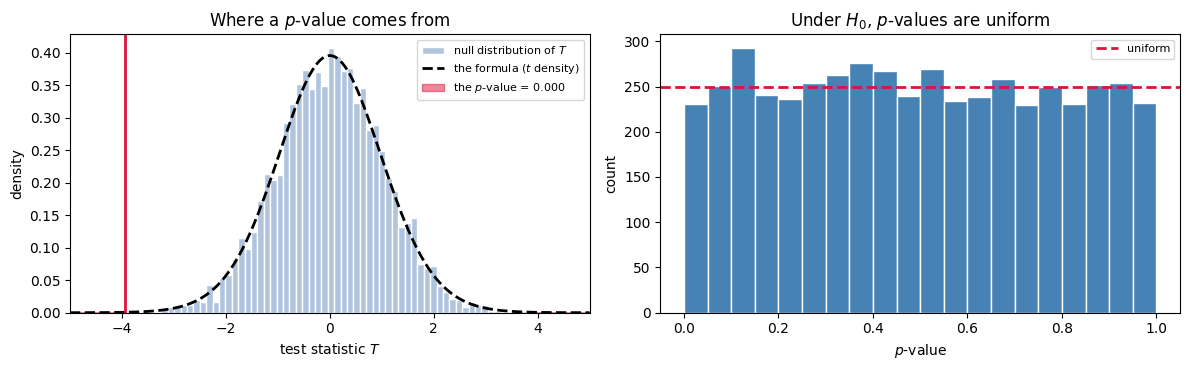

In [3]:
def two_group_tstat(rng_local, n=15, effect=0.0):
    """Two-sample t-test on two groups of size n; effect=0 means H0 is true."""
    a = rng_local.normal(0.0, 1.0, n)
    b = rng_local.normal(effect, 1.0, n)
    return stats.ttest_ind(a, b, equal_var=True)


# One dataset we actually collected, from two groups that really do differ
res_obs = two_group_tstat(rng, effect=1.1)
# 5000 more datasets, all generated with H0 true -> the null distribution
null_T = np.array([two_group_tstat(rng, effect=0.0).statistic for _ in range(5000)])
null_p = np.array([two_group_tstat(rng, effect=0.0).pvalue for _ in range(5000)])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(null_T,
             bins=60,
             density=True,
             color="lightsteelblue",
             edgecolor="w",
             label="null distribution of $T$")
grid = np.linspace(-5, 5, 400)
axes[0].plot(grid,
             stats.t(df=2 * 15 - 2).pdf(grid),
             "k--",
             lw=2,
             label="the formula ($t$ density)")
tail = grid[grid >= abs(res_obs.statistic)]
axes[0].fill_between(tail,
                     stats.t(df=28).pdf(tail),
                     color="crimson",
                     alpha=0.5)
axes[0].fill_between(-tail, 
                     stats.t(df=28).pdf(tail),
                     color="crimson",
                     alpha=0.5,
                     label=f"the $p$-value = {res_obs.pvalue:.3f}")
axes[0].axvline(res_obs.statistic, color="crimson", lw=2)
axes[0].set(xlabel="test statistic $T$", ylabel="density", xlim=(-5, 5),
            title="Where a $p$-value comes from")
axes[0].legend(fontsize=8)

axes[1].hist(null_p, bins=20, range=(0, 1), color="steelblue", edgecolor="w")
axes[1].axhline(len(null_p) / 20, color="crimson", ls="--", lw=2, label="uniform")
axes[1].set(xlabel="$p$-value", ylabel="count",
            title="Under $H_0$, $p$-values are uniform")
axes[1].legend(fontsize=8)
fig.tight_layout()

print(f"fraction of p-values below 0.05 when H0 is TRUE: {np.mean(null_p <= 0.05):.3f}"
      f"   (should be 0.05)")

The left panel is the definition made visible. The histogram is how the statistic
behaves **when nothing is going on**; we consider 5000 datasets simulated with the two group
means equal. The red line is the statistic from the one dataset we actually collected,
where the groups really do differ. The shaded area beyond it, in both tails, *is* the
$p$-value: the chance of a statistic this extreme if there were no difference. The
dashed curve is the Student $t$ density, i.e. the *formula* for that histogram, which
exists here only because we generated Gaussian data. In today's tutorial, Part 1 is what happens when you
trust that formula; Part 2 is what to do when you cannot.

Three common misunderstandings:

* **$p$ is not $\Pr(H_0 \text{ is true})$.** It is a probability computed *assuming*
  $H_0$, not a probability *about* $H_0$. Nothing in this framework assigns
  probabilities to hypotheses.

* **"Not significant" does not mean "no effect".** It means this dataset could not
  distinguish the effect from zero — which may say more about your sample size than
  about the world.

* **A small $p$ says nothing about how big the effect is.** 

# 1 The classical linear model, and when to stop trusting it <a class="anchor" id="linearmodel"></a> [↑](#Table-of-contents)

The linear model is the oldest tool for turning data into statements with error bars. It
gives sharp answers in exchange of four strong assumptions about how the
data were generated. 

This part is about recognising when those assumptions do not
hold, which **in machine-learning practice is most of the time**.

We use the **diabetes** dataset as example: 442 patients, ten baseline
clinical measurements, and disease progression one year later as the target.

In [4]:
diabetes = load_diabetes(scaled=False, as_frame=True)   # scaled=False -> raw, interpretable units
X_df, y_ser = diabetes.data, diabetes.target
feature_names = list(X_df.columns)

X, y = X_df.to_numpy(float), y_ser.to_numpy(float)      # numpy copies, used from Part 2 on
n, p = X.shape

print(f"n = {n} patients, p = {p} features")
print(f"target: disease progression one year after baseline "
      f"(range {y.min():.0f}–{y.max():.0f}, arbitrary units)\n")
X_df.head()

n = 442 patients, p = 10 features
target: disease progression one year after baseline (range 25–346, arbitrary units)



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


In [5]:
import statsmodels.api as sm

X_sm = sm.add_constant(X_df)          # statsmodels asks for an explicit intercept
ols_fit = sm.OLS(y_ser, X_sm).fit()
print(ols_fit.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.518
Model:                            OLS   Adj. R-squared:                  0.507
Method:                 Least Squares   F-statistic:                     46.27
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           3.83e-62
Time:                        16:01:05   Log-Likelihood:                -2386.0
No. Observations:                 442   AIC:                             4794.
Df Residuals:                     431   BIC:                             4839.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -334.5671     67.455     -4.960      0.0

## 1.1 The assumptions, and how badly they fail here <a class="anchor" id="linearmodel_assumptions"></a> [↑](#Table-of-contents)

The linear model used in OLS assumes that each datapoint $(x_i, y_i)$ is generated as per
$$y_i = \beta^T x_i + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2),$$
which packs in four separate assumptions:
- Linearity of $\mathbb{E}[y|x]$

- Homoskedasticity (constant $\sigma^2$)

- Independence across rows

- Normality of the residuals

We will see below that these assumptions are not respected by the data.

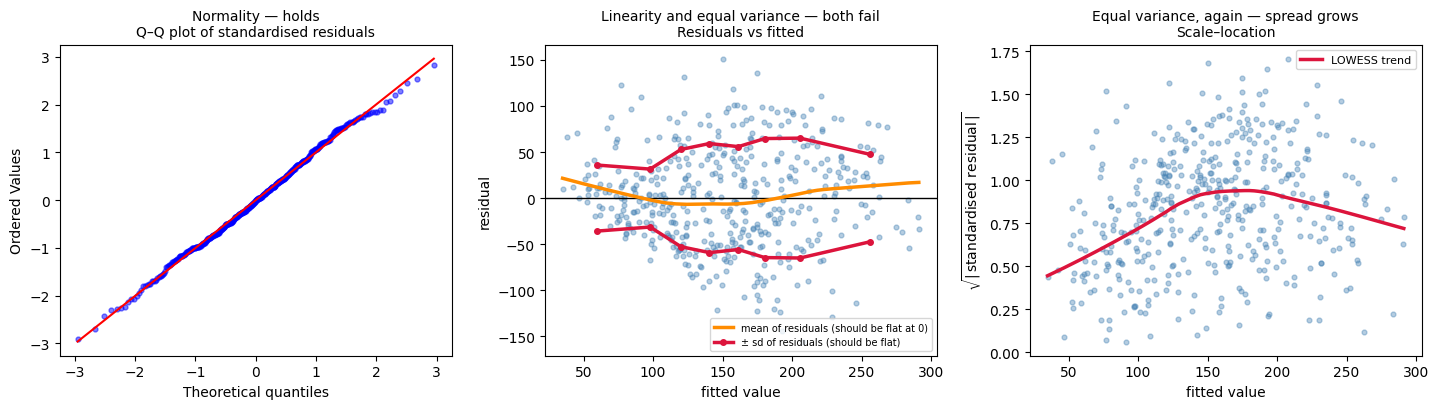

In [6]:
resid = ols_fit.resid.to_numpy()
fitted = ols_fit.fittedvalues.to_numpy()
std_resid = resid / resid.std(ddof=1)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

# (1) NORMALITY of the errors
stats.probplot(std_resid, dist="norm", plot=axes[0])
axes[0].get_lines()[0].set(marker=".", markersize=7, alpha=0.5)
axes[0].set_title("Normality — holds\nQ–Q plot of standardised residuals", fontsize=10)

# (2) LINEARITY (is the mean flat?) and EQUAL VARIANCE (is the spread flat?)
edges = np.quantile(fitted, np.linspace(0, 1, 9))
centres = 0.5 * (edges[:-1] + edges[1:])
binned_sd = np.array([resid[(fitted >= edges[i]) & (fitted <= edges[i + 1])].std()
                      for i in range(8)])
smooth = sm.nonparametric.lowess(resid, fitted, frac=0.6)

ax = axes[1]
ax.scatter(fitted, resid, s=12, alpha=0.4, color="steelblue")
ax.axhline(0, color="k", lw=1)
ax.plot(smooth[:, 0], smooth[:, 1], color="darkorange", lw=2.5,
        label="mean of residuals (should be flat at 0)")
ax.plot(centres, binned_sd, color="crimson", lw=2.5, marker="o", ms=4,
        label="± sd of residuals (should be flat)")
ax.plot(centres, -binned_sd, color="crimson", lw=2.5, marker="o", ms=4)
ax.set(xlabel="fitted value", ylabel="residual")
ax.set_title("Linearity and equal variance — both fail\nResiduals vs fitted", fontsize=10)
ax.legend(fontsize=7, loc="lower right")

# (3) the variance trend on its own, where it is easiest to read
ax = axes[2]
ax.scatter(fitted, np.sqrt(np.abs(std_resid)), s=12, alpha=0.4, color="steelblue")
sl = sm.nonparametric.lowess(np.sqrt(np.abs(std_resid)), fitted, frac=0.6)
ax.plot(sl[:, 0], sl[:, 1], color="crimson", lw=2.5, label="LOWESS trend")
ax.set(xlabel="fitted value", ylabel=r"$\sqrt{|\,\mathrm{standardised\ residual}\,|}$")
ax.set_title("Equal variance, again — spread grows\nScale–location", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()

Two of the four assumptions survive, two do not:

1. **Normality holds.** The Q–Q plot is a straight line. This is the assumption people worry
   about most, and here there is nothing to worry about.

2. **Independence holds**, as far as we can tell. This is probably because we have
   442 unrelated patients rather than a time series or a spatial grid.

3. **Linearity fails, mildly.** The orange curve in the middle panel should sit
   flat on zero. The model is systematically wrong in a way that depends on its
   own prediction.

4. **Equal variance fails** The red envelope varies accross fitted values.

<div class="alert alert-primary">
    <p>
        <b>Conclusion</b>: although the linear model could be used to do predictions on this dataset, any statistical inference carried out with it is not trustworthy.
    </p>
</div>

# 2 Permutation tests <a class="anchor" id="permutation"></a> [↑](#Table-of-contents)

## 2.1 The idea <a class="anchor" id="permutation_idea"></a> [↑](#Table-of-contents)

Classical testing says: *assume a parametric model, derive the null distribution
mathematically.* 

Permutation testing says: *build the null distribution by brute
force, by rearranging the data in a way that is uninformative under $H_0$.*

The formal requirement is **exchangeability**. A sequence $Z_1, \dots, Z_n$ is
exchangeable if its joint distribution is invariant under every permutation $\sigma$:

$$ (Z_1, \dots, Z_n) \;\overset{d}{=}\; (Z_{\sigma(1)}, \dots, Z_{\sigma(n)}). $$

This is weaker than i.i.d. (i.i.d. $\Rightarrow$ exchangeable, not conversely) and it says
nothing about normality, variance, or even the existence of moments.

**The algorithm.** Let $T$ be any statistic, for example a $t$-value, an AUC, or a cross-validated
$R^2$. 

Let $\mathcal{G}$ be a group of transformations that leave the distribution unchanged under $H_0$ (permutations of
the labels, sign flips, within-block shuffles...).

1. compute $T_{\text{obs}}$ on the real (i.e. observed) data

2. for $b = 1, \dots, B$: draw $g_b \in \mathcal{G}$ at random, recompute $T_b$ on the transformed dataset $g_b(\text{data})$

3. report

$$ \hat p = \frac{1 + \#\{b : T_b \ge T_{\text{obs}}\}}{1 + B}$$

## 2.2 How many permutations? <a class="anchor" id="permutation_howmany"></a> [↑](#Table-of-contents)

$B$ controls the Monte Carlo error only — validity holds for any $B$. But:

* the smallest attainable $p$-value is $1/(B+1)$, so with $B = 99$ you can never
  report $p < 0.01$;
* $\hat p$ has binomial standard error $\approx \sqrt{p(1-p)/B}$.

Rules of thumb: $B = 1000$ for exploration; $B \ge 10{,}000$ if you intend to claim
$p < 0.001$ or will apply a multiplicity correction (with $m$ tests and a Bonferroni
threshold $\alpha/m$, you need $B \gtrsim m/\alpha$).

In [ ]:
B_grid = np.array([99, 999, 9_999, 99_999])
true_p = 0.01
mc = pd.DataFrame({
    "B": B_grid,
    "smallest attainable p": 1 / (B_grid + 1)
    })
mc.style.hide(axis="index")

## 2.3 Permuting a partial coefficient: Freedman–Lane <a class="anchor" id="permutation_freedmanlane"></a> [↑](#Table-of-contents)

Section 2.1 left one ingredient unspecified: *what exactly do you shuffle?* That
choice is not a detail — it decides which null hypothesis you are testing.

The naive move is to shuffle $y$ against $X$. But that tests the **global** null
"no feature has any effect", which is not what a regression table reports. The
$t$-test on $\beta_j$ tests a **partial** null: *given the other nine covariates*,
feature $j$ adds nothing. To reproduce that by permutation we must shuffle only
the part of $y$ that the other covariates do not already explain.

That is the **Freedman–Lane** scheme (Freedman & Lane, 1983):

1. regress $y$ on the nuisance covariates $Z = X_{-j}$, keeping the fitted values
   $\hat y_Z$ and the residuals $e = y - \hat y_Z$;
2. permute **the residuals** and rebuild a response: $y^{(b)} = \hat y_Z + \pi_b(e)$;
3. refit the **full** model on $y^{(b)}$ and record the statistic for feature $j$.

In [ ]:
diabetes = load_diabetes(scaled=False, as_frame=True)
X, y = diabetes.data.to_numpy(float), diabetes.target.to_numpy(float)
feature_names = list(diabetes.data.columns)
n, p = X.shape

db_fit = sm.OLS(y, sm.add_constant(X)).fit()
db_dof = int(db_fit.df_resid)
print(f"diabetes: n = {n} patients, p = {p} features\n")
print(pd.DataFrame({"coef": db_fit.params[1:], "t": db_fit.tvalues[1:],
                    "p_value": db_fit.pvalues[1:],
                    "marginal_corr": [np.corrcoef(X[:, j], y)[0, 1] for j in range(p)]},
                   index=feature_names).round(4).to_string())

Let us apply it to `s4`, the cholesterol/HDL ratio — the most interesting row in the
Part 1 table. Its partial $t$-test gives $p = 0.27$, yet its *marginal* correlation
with disease progression is 0.43, among the strongest of the ten. It is heavily
collinear with the other serum measurements, so the model cannot decide which of them
carries the effect.

In [ ]:
def t_statistic(Xd, y, j):
    """Studentised coefficient t_j = beta_j / se(beta_j) for design matrix Xd."""
    XtX_inv = np.linalg.inv(Xd.T @ Xd)
    beta = XtX_inv @ Xd.T @ y
    resid = y - Xd @ beta
    sigma2 = resid @ resid / (len(y) - Xd.shape[1])
    return beta[j] / np.sqrt(sigma2 * XtX_inv[j, j])


def freedman_lane(X, y, feature, B=9999, seed=RANDOM_STATE):
    """Freedman-Lane permutation test for the partial effect of one feature."""
    rng_local = np.random.default_rng(seed)
    Xd = np.column_stack([np.ones(len(y)), X])
    j = feature_names.index(feature) + 1

    t_obs = t_statistic(Xd, y, j)                       # statistic on the real data

    # 1. regress y on the OTHER covariates; keep fitted values and residuals
    Z = np.delete(Xd, j, axis=1)
    fitted_Z = Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
    resid_Z = y - fitted_Z

    # 2-3. permute the residuals, rebuild y, refit the FULL model, record t
    t_null = np.array([t_statistic(Xd, fitted_Z + rng_local.permutation(resid_Z), j)
                       for _ in range(B)])

    p_value = (1 + np.sum(np.abs(t_null) >= np.abs(t_obs))) / (1 + B)
    return t_obs, t_null, p_value


FEATURE, B = "s4", 9999
t_obs, t_null, p_perm = freedman_lane(X, y, FEATURE, B=B)
j = feature_names.index(FEATURE) + 1
dof = int(ols_fit.df_resid)

print(f"{FEATURE}:   t = {t_obs:.4f}")
print(f"   t-test        p = {ols_fit.pvalues.iloc[j]:.4f}   (assumes Gaussian errors)")
print(f"   Freedman-Lane p = {p_perm:.4f}   (assumes only exchangeability, B = {B})")
print(f"\n   sd of the permutation null = {t_null.std():.3f}"
      f"   vs sd of a Student t_{dof} = {np.sqrt(dof/(dof-2)):.3f}")

In [ ]:
# does this hold for s4 only, or for every coefficient in the table?
rows = []
for f_ in feature_names:
    k = feature_names.index(f_) + 1
    _, _, pv = freedman_lane(X, y, f_, B=1999)
    rows.append({"feature": f_, "t": ols_fit.tvalues.iloc[k],
                 "p (t-test)": ols_fit.pvalues.iloc[k], "p (Freedman-Lane)": pv})
comparison = pd.DataFrame(rows).set_index("feature")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(t_null, bins=70, density=True, color="lightsteelblue", edgecolor="w",
        label=f"permutation null ({B} shuffles)")
grid = np.linspace(-4, 4, 400)
ax.plot(grid, stats.t(dof).pdf(grid), "k--", lw=2, label=f"Student $t_{{{dof}}}$ density")
ax.axvline(t_obs, color="crimson", lw=2, label=f"observed $t$ = {t_obs:.2f}")
ax.axvline(-t_obs, color="crimson", lw=2, ls=":")
ax.set(xlabel="$t_{s4}$ under the null", ylabel="density",
       title="The permutation null reproduces the $t$ density")
ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(comparison["p (t-test)"], comparison["p (Freedman-Lane)"], s=45,
           color="steelblue", zorder=3)
for f_, r in comparison.iterrows():
    if r["p (t-test)"] > 0.02:                      # the rest cluster at the origin
        ax.annotate(f_, (r["p (t-test)"], r["p (Freedman-Lane)"]),
                    textcoords="offset points", xytext=(7, -4), fontsize=9)
ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="perfect agreement")
ax.set(xlabel="$p$ from the $t$-test", ylabel="$p$ from Freedman–Lane",
       xlim=(-0.03, 1), ylim=(-0.03, 1), title="All ten coefficients agree")
ax.legend(fontsize=8)
fig.tight_layout()

comparison.round(4)

**Nothing changed.** For `s4`, $p = 0.2735$ becomes $p = 0.2759$. Across all ten
coefficients the two columns agree to within Monte Carlo error, and the right-hand
panel puts every feature on the diagonal.

So when is this worth the 10 000 refits? Two situations, and neither is "replacing a
$t$-test that already works":

* when $n$ is small enough that the central limit theorem cannot rescue you — tens of
  observations, not hundreds
  
* when **there is no formula at all**, which is the usual case in machine learning,
  and which is where we go next.

## 2.4 The real payoff: testing a model that has no formula <a class="anchor" id="permutation_noformula"></a> [↑](#Table-of-contents)

Here is what you cannot do with a $t$-test.

We have a `HistGradientBoostingRegressor`
with a cross-validated $R^2$ around 0.4. Is that better than chance?

`sklearn.model_selection.permutation_test_score` permutes $y$, re-runs the **entire
cross-validation** and refits the model each time. The null is "the features carry no
information about the target at all" — the global null of Section 2.3, which is exactly
the right null for this question.

In [ ]:
from sklearn.model_selection import KFold, permutation_test_score
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(max_iter=100, random_state=RANDOM_STATE)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

score, perm_scores, pvalue = permutation_test_score(
    model, X, y, scoring="r2", cv=cv, n_permutations=99,
    random_state=RANDOM_STATE, n_jobs=2,
)
print(f"cross-validated R^2 = {score:.3f}")
print(f"permutation p-value = {pvalue:.4f}   (smallest attainable: {1/(99+1):.2f})")

In [ ]:
plt.figure(figsize=(7, 3.6))
plt.hist(perm_scores, bins=25, color="lightsteelblue", edgecolor="w", label="null ($y$ permuted)")
plt.axvline(score, color="crimson", lw=2.5, label=f"observed $R^2$ = {score:.3f}")
plt.xlabel("cross-validated $R^2$")
plt.ylabel("count")
plt.title("Permutation test for a gradient boosting model")
plt.legend()
plt.tight_layout()

<div class="alert alert-success">
    <p><b>Exercise</b>:</p>

Look again at the table of Section 2.3: `sex` is the mirror image of `s4`. 

Its correlation with disease progression is only 0.04, yet its $t$-value in the full
model is $-3.9$, with $p$-value $\ll$ 0.01.

1. Following the algorithm of Section 2.1, write a permutation test for the null hypothesis
   *"`sex` and disease progression are unrelated"*: use the absolute correlation
   between `sex` and $y$ as the statistic $T$, shuffle $y$, and take $B = 9999$.

2. Compare your $p$-value with the one returned by `freedman_lane(X, y, "sex")`.

3. The two $p$-values are different. Which null hypothesis does each one test, and how
   can both be right? 
   
   *Hint: look at how `sex` correlates with the other nine features.*

</div>



In [ ]:
# Your work.

In [ ]:
# %load solutions/solution_1.py

# 3 Conformal prediction <a class="anchor" id="conformal"></a> [↑](#Table-of-contents)

## 3.1 From testing to predicting <a class="anchor" id="conformal_testing"></a> [↑](#Table-of-contents)

In Part 1 the object of inference was a **parameter** — is $\beta_j$ zero? In machine learning, we care mostly about the **next observation**: a clinician
does not want a confidence interval on $\beta_{\text{bmi}}$, they want to know where
*this patient's* progression score will land.

The classical answer is the prediction interval you get from the Gaussian linear
model. However, it requires four assumptions, which can fail. 

**Conformal prediction** does the same job assuming only exchangeability and it works for *any* predictive model.

Very briefly, the idea behind conformal prediction is:

<div class="alert alert-primary">
    <p>
        Run your model, measure how wrong it usually is, and use that as the error bar.
    </p>
</div>

More specifically, we proceed as follows:

- Define a **non-conformity score** $s(x, y)$ measuring how badly the point $(x,y)$ fits
what the model expects. 

   - For regression, it could be the absolute residual $|y - \hat\mu(x)|$.

- Compute it on $n$ held-out calibration points, giving $s_1, \dots, s_n$, and let
$s_{n+1}$ be the score of the (unseen) test point.

If $\hat q$ is the $\lceil (n+1)(1-\alpha)\rceil$-th smallest calibration
score, then the set

$$ \mathcal{C}(x_*) = \{\, y : s(x_*, y) \le \hat q \,\} \quad\text{satisfies}\quad
   \boxed{\;\Pr\big(Y_{n+1} \in \mathcal{C}(X_{n+1})\big) \;\ge\; 1-\alpha\;} $$

in **finite samples**, for **any** model, **any** data distribution. 

| | Part 1: OLS prediction interval | Part 3: conformal prediction |
|---|---|---|
| Assumptions | linear, Gaussian, homoskedastic, independent | exchangeable |
| Model allowed | linear regression only | anything |
| Guarantee | exact, and holds for each $x$ separately | **marginal** — on average over $x$ |
| Cost | none | one held-out calibration set |

## 3.2 Split conformal prediction <a class="anchor" id="conformal_split"></a> [↑](#Table-of-contents)

Running the above procedure literally means refitting for every candidate $y$. The practical
version splits the data into three parts: **train**, **calibration**, **test**.

1. Fit any model $\hat\mu$ on the training set. *It is never refitted again.*

2. On the $n$ calibration points compute the score $s_i = s(X_i, Y_i)$ — for
   regression, the absolute residual $|y_i - \hat\mu(x_i)|$.

3. Compute the **conformal quantile**
   $\hat q = $ the $\lceil (n+1)(1-\alpha)\rceil$-th smallest of $s_1,\dots,s_n$.

4. Return $\mathcal{C}(x_*) = \{y : s(x_*,y) \le \hat q\}$, which in this case is simply
   $[\hat\mu(x_*) - \hat q, \hat\mu(x_*) + \hat q]$.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

diabetes = load_diabetes(scaled=False, as_frame=True)
X, y = diabetes.data.to_numpy(float), diabetes.target.to_numpy(float)
feature_names = list(diabetes.data.columns)
n, p = X.shape

def conformal_quantile(scores, alpha):
    """The ceil((n+1)(1-alpha))-th smallest score — the finite-sample conformal quantile."""
    scores = np.asarray(scores, float)
    n = len(scores)
    level = np.ceil((n + 1) * (1 - alpha)) / n
    if level > 1:                      # n too small for this alpha: no finite bound exists
        return np.inf
    return np.quantile(scores, level, method="higher")

ALPHA = 0.10   # we target 90% coverage

X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.5, random_state=RANDOM_STATE)
X_cal, X_test, y_cal, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=RANDOM_STATE)
print(f"train {len(y_train)} | calibration {len(y_cal)} | test {len(y_test)}")

# step 1
mu_hat = make_pipeline(StandardScaler(), RidgeCV()).fit(X_train, y_train)
# step 2
scores_cal = np.abs(y_cal - mu_hat.predict(X_cal))
# step 3
q_hat = conformal_quantile(scores_cal, ALPHA)
# step 4
pred_test = mu_hat.predict(X_test)
lo, hi = pred_test - q_hat, pred_test + q_hat
covered = (y_test >= lo) & (y_test <= hi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(scores_cal, bins=30, color="lightsteelblue", edgecolor="w")
axes[0].axvline(q_hat, color="crimson", lw=2.5, label=rf"$\hat q$ = {q_hat:.0f}")
axes[0].set(xlabel="non-conformity score $|y - \\hat\\mu(x)|$", ylabel="count",
            title="Calibration scores")
axes[0].legend()

order = np.argsort(pred_test)
axes[1].fill_between(np.arange(len(y_test)), lo[order], hi[order],
                     color="steelblue", alpha=0.25, label="90% conformal interval")
axes[1].plot(pred_test[order], color="steelblue", lw=1.5, label=r"$\hat\mu(x)$")
axes[1].scatter(np.arange(len(y_test))[covered[order]], y_test[order][covered[order]],
                s=12, color="k", label="covered")
axes[1].scatter(np.arange(len(y_test))[~covered[order]], y_test[order][~covered[order]],
                s=30, color="crimson", marker="x", label="missed")
axes[1].set(xlabel="test points, sorted by prediction", ylabel="disease progression",
            title="Split conformal intervals (diabetes)")
axes[1].legend(fontsize=8)
fig.tight_layout()

Note the shape of the right-hand panel: the band has **constant width**. Split
conformal with absolute-residual scores treats every patient as equally predictable.
Part 1 showed that real regression errors are not equally spread out, and the
diabetes data is no exception...

## 3.3 The hard limit: **marginal** $\ne$ **conditional** coverage <a class="anchor" id="conformal_conditional"></a> [↑](#Table-of-contents)

The conformal prediction guarantee that we showed before is

$$ \Pr\big(Y \in \mathcal{C}(X)\big) \ge 1-\alpha \qquad\text{(marginal — averaged over } X\text{)} $$

and **not**

$$ \Pr\big(Y \in \mathcal{C}(X) \mid X = x\big) \ge 1-\alpha \quad \text{for every } x \qquad\text{(conditional)}. $$

This means that a procedure can hit 90% overall while covering 100% of the easy cases and 70% of the
hard ones. For a clinical or credit-scoring model, this is a failure mode that we would prefer to avoid: the under-covered sub-population is usually the one already badly served.

In practice, it is possible to choose different strategies for the score function that can yield intervals of varying size that respect the target conditional coverage. Note, however, that there are no formal guarantees as for the marginal case. 

Consider a dataset where the conditional law varies with $x$ as in:

$$Y \mid X=x \sim \mathcal{N}\big(3\sin x + \tfrac{x}{2},\, \sigma(x)^2\big)$$

with $\sigma(x) = 0.3 + 0.35x$ on $[0,10]$ — the noise standard deviation grows more than
tenfold across the range. 

Under this Gaussian model, we consider the three score candidates with $\hat\mu, \hat\sigma$ fitted
on the training set:

* absolute residual: $|y - \hat\mu(x)|$ — the naive baseline

* studentised: $|y - \hat\mu(x)| / \hat\sigma(x)$

* CQR: from two quantile-regression models.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

SD_FACTOR = np.sqrt(np.pi / 2)        # E|N(0,s)| = s*sqrt(2/pi), so sd = factor * E|resid|

# define dataset with heteroscedastic noise, for the conditional coverage experiment
def make_hetero(n, rng_local):
    x = rng_local.uniform(0, 10, n)
    sd = 0.3 + 0.35 * x                       # noise grows with x
    return x.reshape(-1, 1), 3 * np.sin(x) + 0.5 * x + rng_local.normal(0, sd)

# generate datasets
rng_h = np.random.default_rng(3)
Xh_tr, yh_tr = make_hetero(2000, rng_h)
Xh_cal, yh_cal = make_hetero(1000, rng_h)
Xh_te, yh_te = make_hetero(20000, rng_h)

# estimators for the mean and the standard deviation of the noise
# (min_samples_leaf=50: each leaf averages at least 50 points, which keeps the bands smooth)
mu_h = GradientBoostingRegressor(min_samples_leaf=50).fit(Xh_tr, yh_tr)
sigma_h = GradientBoostingRegressor(min_samples_leaf=50).fit(Xh_tr, np.abs(yh_tr - mu_h.predict(Xh_tr)))
qlo_h = GradientBoostingRegressor(loss="quantile", alpha=ALPHA / 2, random_state=0).fit(Xh_tr, yh_tr)
qhi_h = GradientBoostingRegressor(loss="quantile", alpha=1 - ALPHA / 2, random_state=0).fit(Xh_tr, yh_tr)

mu_c, mu_t = mu_h.predict(Xh_cal), mu_h.predict(Xh_te)
sd_c = np.maximum(sigma_h.predict(Xh_cal), 1e-3) * SD_FACTOR
sd_t = np.maximum(sigma_h.predict(Xh_te), 1e-3) * SD_FACTOR

# Each score gives a calibrated quantile q_hat and a rule turning it into an interval.
# We keep the rule as a function so we can apply it to the test set (for evaluation)
# and to a dense grid of x (for plotting).
band_rules = {}

# (1) absolute residual
q = conformal_quantile(np.abs(yh_cal - mu_c), ALPHA)
band_rules["absolute residual"] = lambda m, sd, lo, hi, q=q: (m - q, m + q)

# (2) studentised / locally weighted
q = conformal_quantile(np.abs(yh_cal - mu_c) / sd_c, ALPHA)
band_rules["studentised"] = lambda m, sd, lo, hi, q=q: (m - q * sd, m + q * sd)

# (3) CQR
s_cqr = np.maximum(qlo_h.predict(Xh_cal) - yh_cal, yh_cal - qhi_h.predict(Xh_cal))
q = conformal_quantile(s_cqr, ALPHA)
band_rules["CQR"] = lambda m, sd, lo, hi, q=q: (lo - q, hi + q)


def bands_at(Xq):
    """Apply every rule at the covariates Xq."""
    m = mu_h.predict(Xq)
    sd = np.maximum(sigma_h.predict(Xq), 1e-3) * SD_FACTOR
    lo_q, hi_q = qlo_h.predict(Xq), qhi_h.predict(Xq)
    return {k: rule(m, sd, lo_q, hi_q) for k, rule in band_rules.items()}


intervals = bands_at(Xh_te)

# split the test points into 5 bins of x, to measure coverage conditional on x
xs = Xh_te.ravel()
bins = np.linspace(0, 10, 6)
idx = np.digitize(xs, bins[1:-1])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sub = rng_h.choice(len(xs), 700, replace=False)
palette = dict(zip(intervals, ["tab:red", "tab:blue", "tab:green"]))

# draw the bands on a dense ordered grid: same models, same q_hat, just legible
x_grid = np.linspace(0.05, 9.95, 400).reshape(-1, 1)
axes[0].scatter(xs[sub], yh_te[sub], s=6, alpha=0.3, color="grey")
for name, (lo_, hi_) in bands_at(x_grid).items():
    axes[0].plot(x_grid.ravel(), lo_, lw=1.8, color=palette[name], label=name)
    axes[0].plot(x_grid.ravel(), hi_, lw=1.8, color=palette[name])
axes[0].set(xlabel="x", ylabel="y", title="90% prediction bands from three scores")
axes[0].legend(fontsize=8, loc="upper left")

centres = 0.5 * (bins[:-1] + bins[1:])
for name, (lo_, hi_) in intervals.items():
    cov = (yh_te >= lo_) & (yh_te <= hi_)
    axes[1].plot(centres, [cov[idx == g].mean() for g in range(5)], "o-",
                 color=palette[name], label=name)
axes[1].axhline(1 - ALPHA, color="k", ls="--", label=r"target $1-\alpha$")
axes[1].set(xlabel="x", ylabel="coverage", title="Coverage conditional on $x$", ylim=(0.6, 1.03))
axes[1].legend(fontsize=8)
fig.tight_layout()

<div class="alert alert-success">
    <p><b>Exercise</b>:</p>

Conformal prediction assumes that the calibration and test points are
exchangeable. What happens when they are not?

1. In the example above, use `conformal_quantile` to compute $\hat q$ for the
   absolute-residual score with only the calibration points that have $x < 5$. Then measure
   the coverage of the resulting intervals on the test points with $x \ge 5$.

2. Do the same the other way round: calibrate on $x \ge 5$ and test on $x < 5$.

3. Which assumption is broken, and why does the coverage move in opposite directions?

</div>

In [ ]:
# Your work.

In [ ]:
# %load solutions/solution_2.py

# 4 Probabilistic calibration of classifiers <a class="anchor" id="calibration"></a> [↑](#Table-of-contents)

## 4.1 What `predict_proba` does and does not promise <a class="anchor" id="calibration_promise"></a> [↑](#Table-of-contents)

Every scikit-learn classifier has a `predict_proba`, but almost none of them promises the
numbers are probabilities.

The standard notion in machine learning is **confidence calibration** : writing $\hat Y = \arg\max_k \hat p_k(X)$ and $\hat P = \max_k \hat p_k(X)$,

$$ \Pr\big(\hat Y = Y \;\big|\; \hat P = c\big) = c \qquad \text{for all } c \in [0,1]. $$

Among all the samples the model called with confidence 0.8, 80% should be right.

We switch to `digits`, with a binary target ("is the digit $\ge 5$?") and maintain the previous three-way split for the dataset.

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss, log_loss

# load dataset and transform to a binary classification problem
digits = load_digits()
Xd_all, yd_multi = digits.data, digits.target
yd_bin = (yd_multi >= 5).astype(int)

# split into train, calibration, and test sets
Xd_tr, Xd_rest, ym_tr, ym_rest, yb_tr, yb_rest = train_test_split(
    Xd_all, yd_multi, yd_bin, test_size=0.5, random_state=RANDOM_STATE, stratify=yd_multi)
Xd_cal, Xd_te, ym_cal, ym_te, yb_cal, yb_te = train_test_split(
    Xd_rest, ym_rest, yb_rest, test_size=0.5, random_state=RANDOM_STATE, stratify=ym_rest)

# consider three classifiers, all of which can produce probability estimates
classifiers = {
    "GaussianNB": GaussianNB(),
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
fitted = {name: clf.fit(Xd_tr, yb_tr) for name, clf in classifiers.items()}
probs = {name: clf.predict_proba(Xd_te)[:, 1] for name, clf in fitted.items()}

## 4.2 Calibration curve <a class="anchor" id="calibration_curve"></a> [↑](#Table-of-contents)

The usual diagnostic to check how trustful are the probability estimates is the calibration curve, which is built as:

- Train the classififer on a training set

- For each $x_i, y_i$ in the calibration set, calculate the estimated probability $\hat{p}_i$
    - In a binary classification problem, this corresponds to the estimated probability of $y_i$ being 1

- Construct $B$ bins (i.e. non-overlapping intervals $I_b \subset [0, 1]$) and group the $\hat{p}_{i}$ accordingly

- For each bin $b \in [1, \dots, B]$, calculate the average predicted probability: $\hat{p}_b = \dfrac{1}{\sum_{i = 1}\boldsymbol{1}(\hat{p}_i \in I_b)}\displaystyle\sum_{i = 1} \hat{p}_i\boldsymbol{1}(\hat{p}_i \in I_b)$

- Calculate the fraction of data points in class 1 in each bin: $\tilde{p}_b = \dfrac{1}{\sum_{i = 1}\boldsymbol{1}(\hat{p}_i \in I_b)}\displaystyle\sum_{i = 1} y_i\boldsymbol{1}(\hat{p}_i \in I_b)$

- Plot a curve with $\hat{p}_b$ values in the x-axis and $\tilde{p}_b$ values in the y-axis

- A curve that is close to a diagonal in $[0, 1] \times [0,1]$ indicates that the classifier is calibrated. 

In [ ]:
markers = {"GaussianNB": "o", "LogisticRegression": "s", "RandomForest": "^"}
colors  = {"GaussianNB": "tab:blue", "LogisticRegression": "tab:orange",
           "RandomForest": "tab:green"}
N_BINS = 10

fig, axd = plt.subplot_mosaic(
    [["cal", "GaussianNB"],
     ["cal", "LogisticRegression"],
     ["cal", "RandomForest"]],
    figsize=(12, 5.6), width_ratios=[1.3, 1], sharex=True,
)

ax = axd["cal"]
ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="perfectly calibrated")
for name, pr in probs.items():
    frac_pos, mean_pred = calibration_curve(yb_te, pr, n_bins=N_BINS)
    ax.plot(mean_pred, frac_pos, lw=1.5, color=colors[name], alpha=.7, zorder=2)
    ax.scatter(mean_pred, frac_pos, s=20, marker=markers[name],
               color=colors[name], label=name, zorder=3)
ax.set(xlabel="predicted probability", ylabel="observed fraction of positives",
       title="Calibration curves")
ax.legend(fontsize=9, loc="upper left")

for name, pr in probs.items():
    a = axd[name]
    a.hist(pr, bins=30, range=(0, 1), color=colors[name], alpha=.85)
    a.set(ylabel="count", yscale="log", ylim=(0.7, 700))
    a.text(.5, .9, name, transform=a.transAxes, ha="center", va="top",
           fontsize=9, fontweight="bold")
axd["RandomForest"].set_xlabel("predicted probability")
axd["GaussianNB"].set_title("Where the scores actually land")
fig.tight_layout()

We observe three classic behaviours, each with a known mechanism:

* **`GaussianNB`** pushes everything to 0 and 1. Naive Bayes multiplies 64 pixel
  likelihoods treated as conditionally independent but in fact heavily correlated, so
  the same evidence is counted many times over. Any badly misspecified *generative*
  model does this

* **`LogisticRegression`** sits almost on the diagonal. Minimising the log
  loss with the canonical link yields a **balance property**, which makes the model
  calibrated in-sample when it is well specified and not over-regularised

* **`RandomForest`** shows a characteristic S-shape and almost never predicts near
  0 or 1. Averaging over bootstrapped trees pulls extreme predictions toward the
  middle: for a case that should get $p = 0$, bagging can only produce 0 if *every*
  tree says 0, and variance in the base trees guarantees some will not.

## 4.3 Fixing it: post-hoc calibration <a class="anchor" id="calibration_posthoc"></a> [↑](#Table-of-contents)

It is possible to *post-process* a classifier so to make its probability estimated calibrated. 

For this, one should fit a monotone map $g$ from the model's score
to a probability, **on data the model has never seen**. Two standard choices are:

| Method | Model | Parameters | Use when |
|---|---|---|---|
| **Sigmoid** | $g(f) = 1/(1 + e^{Af+B})$ | 2 | small calibration set; sigmoid-shaped distortion (SVM, RF, boosting) |
| **Isotonic** | any non-decreasing step function | non-parametric | $\gtrsim 1000$ calibration points; arbitrary monotone distortion |

In scikit-learn, `CalibratedClassifierCV` uses cross-validation to both estimate the parameters of a classifier and subsequently calibrate it. Previously fitted classifiers can be calibrated by wrapping the model in a `FrozenEstimator`. In this case, all provided data is used for calibration. The user has to take care manually that data for model fitting and calibration are disjoint. The calibration is based on the `decision_function` method of the estimator if it exists, else on `predict_proba`.

In [ ]:
from sklearn.frozen import FrozenEstimator

calibrated = {}
for name, clf in fitted.items():
    for method in ["sigmoid", "isotonic"]:
        cal = CalibratedClassifierCV(FrozenEstimator(clf), method=method).fit(Xd_cal, yb_cal)
        calibrated[(name, method)] = cal.predict_proba(Xd_te)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), sharey=True)
for ax, name in zip(axes, fitted):
    ax.plot([0, 1], [0, 1], "k--", lw=1.2)
    for method, pr2 in [("none", probs[name])] + [(m, calibrated[(name, m)]) for m in ["sigmoid", "isotonic"]]:
        f_pos, m_pred = calibration_curve(yb_te, pr2, n_bins=8, strategy="quantile")
        ax.plot(m_pred, f_pos, marker="o", lw=2, label=method)
    ax.set(xlabel="predicted probability", title=name)
    ax.legend(fontsize=8)
axes[0].set_ylabel("observed fraction of positives")
fig.suptitle("Effect of post-hoc calibration", y=1.02)
fig.tight_layout()

<div class="alert alert-success">
    <p><b>Exercise</b>:</p>

Post-hoc calibration applies a monotone map to the scores of a model. What does it change,
and what does it leave untouched?

1. For `GaussianNB` and `RandomForest`, compute the accuracy and the AUC on the test set,
   before and after isotonic calibration. The test probabilities are in `probs[name]` and
   `calibrated[(name, "isotonic")]`.

2. Calibration changes the accuracy of `GaussianNB`, but not that of `RandomForest`. Why?

3. Do the same for `DummyClassifier(strategy="prior")` from `sklearn.dummy`, which predicts
   the base rate of the training set for every digit, and look at its calibration curve.

4. The dummy classifier is perfectly calibrated. Would you deploy it?

</div>

In [ ]:
# Your work.

In [ ]:
# %load solutions/solution_3.py